<a id="top"></a>

# Лабораторная работа 01. Дополнительное задание КТвД
## Сколько страниц товаров просматривают перед покупкой?

**Цель:** проверить, связано ли число просмотренных товарных страниц с покупкой, и построить генератор этого числа по данным интернет-магазина.

**Данные:** Online Shoppers Purchasing Intention (UCI, 2018), 12 330 сессий. [Описание набора](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), [DOI: 10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q).

**Выполнила:** Каширина Олеся Сергеевна (ИСУ: 501195)

<a id="toc"></a>

### Содержание

1. [Данные и случайный эксперимент](#setup)
2. [Random Variable 01: количество товарных страниц](#rv1)
   - [Description и математическое определение](#rv1-description)
   - [EDA, распределение и нормализация](#rv1-eda)
3. [Random Variable 02: факт покупки](#rv2)
   - [Description и математическое определение](#rv2-description)
   - [EDA и распределение Бернулли](#rv2-eda)
4. [Проверка зависимости](#independence)
5. [Выборка и состоятельность оценок](#sampling)
6. [Генератор случайных чисел и тесты](#generator)
7. [Выводы и cat_mark_table](#resume)
8. [Литература](#sources)

В HTML показаны расчёты, графики и выводы. Код можно посмотреть в Jupyter Notebook.

<a id="setup"></a>

## 1. Данные и единица наблюдения

Одна строка датасета соответствует одной сессии интернет-магазина. По описанию UCI, в течение года от каждого пользователя оставили одну сессию.

Для анализа взяты два столбца:

- $X$ = `ProductRelated`: сколько товарных страниц просмотрено, шт.
- $Y$ = `Revenue`: была покупка ($1$) или нет ($0$).

Считаем случайным событием выбор сессии из набора. В уже записанном CSV значения фиксированы. В расчётах ниже эти 12 330 сессий служат конечной генеральной совокупностью.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'online_shoppers_intention.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'online_shoppers_intention.csv').exists(), 'Не найден исходный CSV'
sys.path.insert(0, str(ROOT))

from src.generator import EmpiricalGenerator, kolmogorov_distance, dkw_threshold
from src.stats_utils import load_sessions, contingency_analysis, wilson_interval, PAGE_LABELS, PAGE_BINS

sns.set_theme(style='whitegrid', context='notebook', palette=['#2563eb','#f97316','#059669','#7c3aed'])
plt.rcParams.update({'figure.dpi': 118, 'axes.titlesize': 13, 'axes.labelsize': 11,
                     'font.family': 'DejaVu Sans', 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, GREEN = '#2563eb', '#f97316', '#059669'
SEED = 2026
df = load_sessions(str(ROOT / 'data' / 'online_shoppers_intention.csv'))
x = df['ProductRelated'].to_numpy(dtype=int)
y = df['Revenue'].to_numpy(dtype=int)
N = len(df)
print(f'Размер: {N:,} сессий × {df.shape[1]} признаков; пропусков: {df.isna().sum().sum()}')
display(df[['ProductRelated','Revenue','VisitorType','Weekend']].head())

Размер: 12,330 сессий × 18 признаков; пропусков: 0


,ProductRelated,Revenue,VisitorType,Weekend
0,1,0,Returning_Visitor,False
1,2,0,Returning_Visitor,False
2,1,0,Returning_Visitor,False
3,2,0,Returning_Visitor,False
4,10,0,Returning_Visitor,True


<a id="rv1"></a>

## 2. Random Variable 01: число товарных страниц

<a id="rv1-description"></a>

### 2.1. Description. Почему $X$ случайная величина

Равновероятно выбираем одну из $N=12\,330$ сессий. Для этого эксперимента:

$$
\Omega=\{1,\ldots,N\},\quad \mathcal{F}=2^{\Omega},\quad
P(\{i\})=\frac1N,\qquad N=12\,330.
$$

Пусть $X(i)=x_i$, где $x_i$ обозначает число просмотренных страниц в сессии $i$. Тогда

$$
X:\Omega\to\mathbb{Z}_{\ge 0},\qquad
\{\omega:X(\omega)\le t\}\in\mathcal F\quad\forall t\in\mathbb R.
$$

Множество $\{\omega:X(\omega)\le t\}$ при любом $t$ принадлежит $\mathcal F$, так как $\mathcal F$ содержит все подмножества $\Omega$. Значит, $X$ измерима и является дискретной случайной величиной.

В данных $X$ принимает 311 различных значений от 0 до 705, поэтому $\operatorname{Var}(X)>0$. Даже среди возвращающихся пользователей в будни число просмотров различается. До начала сессии его нельзя точно получить только из типа пользователя и дня недели. При известной истории кликов число страниц, конечно, можно подсчитать: случайность здесь связана с выбором сессии и неизвестным заранее поведением.

In [2]:
mean_x = x.mean()
var_x = x.var(ddof=0)
print(f'X: min={x.min()}, max={x.max()}, различных значений={np.unique(x).size}')
print(f'E_N[X]={mean_x:.3f} страниц; Var_N(X)={var_x:.3f} страниц²')
assert np.unique(x).size > 1 and var_x > 0

# Проверяем разброс при одинаковом типе пользователя и признаке выходного:
mask = (df['VisitorType'] == 'Returning_Visitor') & (df['Weekend'] == False)
subset = df.loc[mask, 'ProductRelated'].to_numpy()
print(f'При одинаковых VisitorType=Returning_Visitor и Weekend=False: '
      f'n={len(subset)}, разных X={np.unique(subset).size}, Var(X|G)={subset.var():.2f} > 0')

X: min=0, max=705, различных значений=311
E_N[X]=31.731 страниц; Var_N(X)=1977.910 страниц²
При одинаковых VisitorType=Returning_Visitor и Weekend=False: n=8169, разных X=284, Var(X|G)=2151.91 > 0


<a id="rv1-eda"></a>

### 2.2. EDA & Distribution

Среднее число страниц равно 31,73, медиана равна 18. Разница связана с длинным правым хвостом: максимум достигает 705 страниц. Первую гистограмму ограничиваем 99-м процентилем, чтобы были видны частые значения. На втором графике все сессии показаны после преобразования $\ln(1+X)$. При расчёте статистик ничего не отбрасываем.

Эмпирические вероятности и функция распределения:

$$
\widehat p_k=\frac{1}{N}\sum_{i=1}^N\mathbf1\{x_i=k\},\qquad
\widehat F_N(t)=\frac1N\sum_{i=1}^N\mathbf1\{x_i\le t\}.
$$

Доля наблюдений выше P99: 0.99%; дисперсия / среднее: 62.3


,"X, страниц"
count,12330.00
mean,31.73
std,44.48
min,0.00
25%,7.00
50%,18.00
75%,38.00
90%,74.00
95%,109.00
99%,221.00


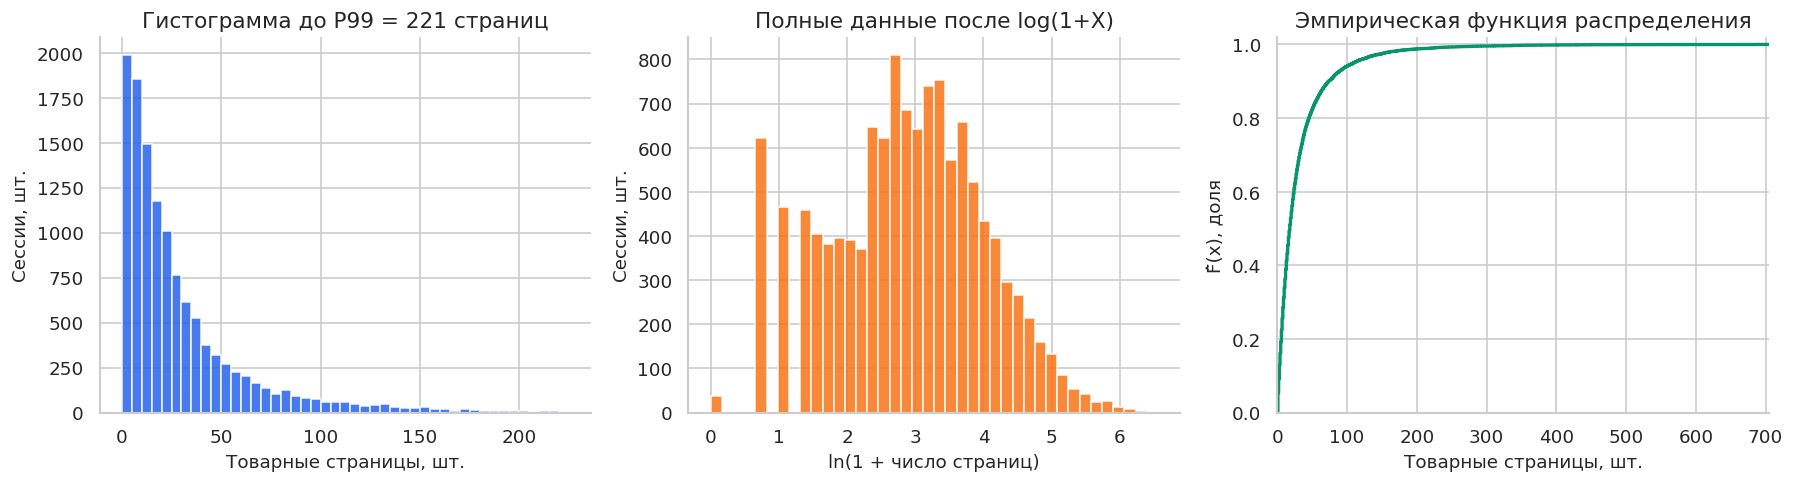

In [3]:
desc_x = pd.Series(x).describe(percentiles=[.25,.5,.75,.90,.95,.99]).to_frame('X, страниц')
display(desc_x.round(2))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
p99 = np.percentile(x, 99)
axes[0].hist(x[x <= p99], bins=np.arange(0, int(p99) + 6, 5), color=BLUE, alpha=.85)
axes[0].set(title=f'Гистограмма до P99 = {p99:.0f} страниц', xlabel='Товарные страницы, шт.', ylabel='Сессии, шт.')
axes[1].hist(np.log1p(x), bins=40, color=ORANGE, alpha=.85)
axes[1].set(title='Полные данные после log(1+X)', xlabel='ln(1 + число страниц)', ylabel='Сессии, шт.')
sorted_x = np.sort(x)
axes[2].step(sorted_x, np.arange(1, N+1)/N, where='post', color=GREEN, lw=2)
axes[2].set(title='Эмпирическая функция распределения', xlabel='Товарные страницы, шт.', ylabel='F̂(x), доля', xlim=(0, x.max()), ylim=(0,1.02))
fig.tight_layout()
plt.show()
print(f'Доля наблюдений выше P99: {(x > p99).mean():.2%}; дисперсия / среднее: {x.var(ddof=0)/x.mean():.1f}')

### 2.3. Нормализация

Стандартизируем $X$, чтобы получить величину без единиц измерения:

$$Z_X=\frac{X-\bar x}{s_X},\qquad
s_X=\sqrt{\frac{1}{N}\sum_{i=1}^N(x_i-\bar x)^2}.$$

После стандартизации среднее равно нулю, стандартное отклонение равно единице (`ddof=0`). Форма распределения не меняется. Преобразование $\ln(1+X)$ отдельно уменьшает правую асимметрию, но результат измеряется уже не в страницах.

In [4]:
z_x = (x - x.mean()) / x.std(ddof=0)
print(f'Стандартизированная X: mean={z_x.mean():.6f}; std={z_x.std(ddof=0):.6f}')
print(f'Асимметрия исходной X: {stats.skew(x):.2f}; после log(1+X): {stats.skew(np.log1p(x)):.2f}')
assert abs(z_x.mean()) < 1e-12 and abs(z_x.std(ddof=0) - 1) < 1e-12

Стандартизированная X: mean=0.000000; std=1.000000
Асимметрия исходной X: 4.34; после log(1+X): -0.05


<a id="rv2"></a>

## 3. Random Variable 02: покупка

<a id="rv2-description"></a>

### 3.1. Description. Почему $Y$ случайная величина

Для выбранной сессии введём

$$Y(i)=\begin{cases}1,&\text{сессия }i\text{ завершилась покупкой},\\0,&\text{иначе}.\end{cases}$$

События $\{Y=0\}$ и $\{Y=1\}$ принадлежат $\mathcal F$, поэтому $Y$ измерима. В наборе встречаются оба исхода: $0<P(Y=1)<1$, а дисперсия положительна.

Это распределение Бернулли с параметром $p=P(Y=1)$:

$$P(Y=y)=p^y(1-p)^{1-y},\quad y\in\{0,1\},\qquad
\mathbb E Y=p,\quad\operatorname{Var}(Y)=p(1-p).$$

Долю покупок оценим по формуле $\hat p=\frac1N\sum_{i=1}^N y_i$. Среди возвращающихся пользователей в будни есть оба исхода. Значит, тип пользователя и день недели не определяют результат покупки однозначно.

In [5]:
p_hat = y.mean()
lo, hi = wilson_interval(int(y.sum()), N)
print(f'Без покупки: {(y==0).sum():,}; с покупкой: {y.sum():,}; p̂={p_hat:.5f}')
print(f'Среднее={y.mean():.5f}; дисперсия={y.var(ddof=0):.5f}; p̂(1-p̂)={p_hat*(1-p_hat):.5f}')
group_y = df.loc[mask, 'Revenue'].astype(int)
conditional_p = group_y.mean()
print(f'P̂(Y=1 | Returning_Visitor, будни) = {conditional_p:.4f}, '
      f'Var̂(Y|G) = {conditional_p*(1-conditional_p):.4f} > 0')
assert 0 < p_hat < 1 and 0 < conditional_p < 1

Без покупки: 10,422; с покупкой: 1,908; p̂=0.15474
Среднее=0.15474; дисперсия=0.13080; p̂(1-p̂)=0.13080
P̂(Y=1 | Returning_Visitor, будни) = 0.1318, Var̂(Y|G) = 0.1145 > 0


<a id="rv2-eda"></a>

### 3.2. EDA

Из 12 330 сессий 1 908 закончились покупкой, доля составила 15,47%. Покажем её вместе с 95%-м интервалом Уилсона. Интервал имеет смысл при случайном отборе независимых сессий из сопоставимой популяции. Доля в самом CSV известна точно.

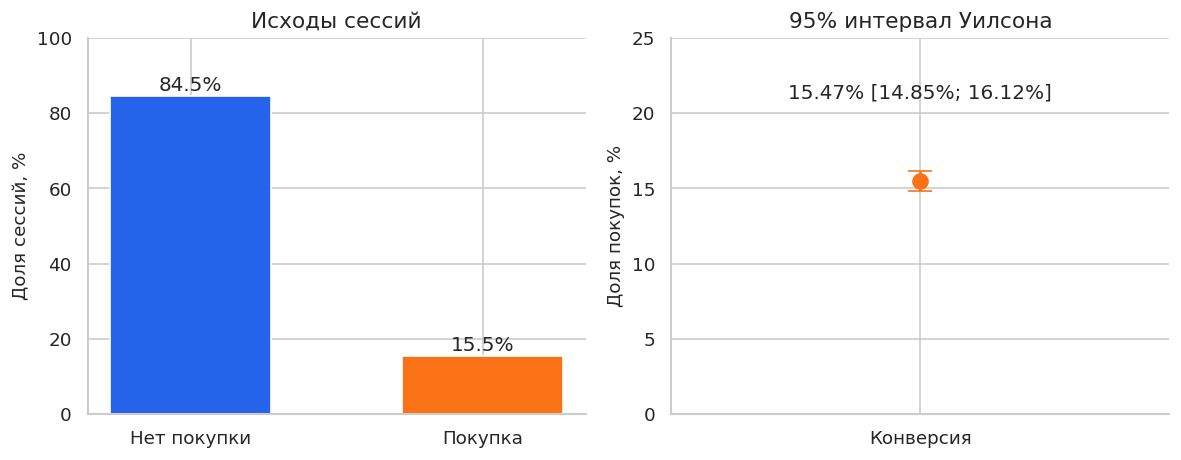

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(['Нет покупки', 'Покупка'], [(1-p_hat)*100, p_hat*100], color=[BLUE,ORANGE], width=.55)
axes[0].set(ylabel='Доля сессий, %', title='Исходы сессий', ylim=(0,100))
for i, value in enumerate([(1-p_hat)*100, p_hat*100]):
    axes[0].text(i, value+1.5, f'{value:.1f}%', ha='center')
axes[1].errorbar([0], [p_hat*100], yerr=[[100*(p_hat-lo)],[100*(hi-p_hat)]],
                 fmt='o', color=ORANGE, markersize=9, capsize=7)
axes[1].set(xlim=(-.6,.6), ylim=(0,25), xticks=[0], xticklabels=['Конверсия'],
            ylabel='Доля покупок, %', title='95% интервал Уилсона')
axes[1].text(0, 21, f'{p_hat:.2%} [{lo:.2%}; {hi:.2%}]', ha='center')
fig.tight_layout()
plt.show()

<a id="independence"></a>

## 4. Independence & Estimations: связь просмотров с покупкой

Если $X$ и $Y$ независимы, то $P(X\in A,Y\in B)=P(X\in A)P(Y\in B)$ для любых $A,B$. В частности, доля покупок не должна систематически различаться между группами по числу просмотров.

Для проверки разобьём $X$ на интервалы: $0$, $1$–$5$, $6$–$15$, $16$–$30$, $31$–$60$, $61+$ страниц. Обозначим группу через $B(X)$.

$$
H_0:\ B(X)\ \text{и}\ Y\ \text{независимы};\qquad
H_1:\ \text{между ними есть связь}.
$$

По таблице сопряжённости вычислим критерий Пирсона:

$$
\chi^2=\sum_{j=1}^{6}\sum_{y=0}^1
\frac{(O_{jy}-E_{jy})^2}{E_{jy}},\qquad
E_{jy}=\frac{O_{j\cdot}O_{\cdot y}}{N}.
$$

Степеней свободы $(6-1)(2-1)=5$. Используем уровень значимости $\alpha=0.05$ и проверяем, что ожидаемые частоты не меньше 5. Для оценки силы связи рассчитаем $V$ Крамера. Корреляция Спирмена нужна как дополнительная проверка без группировки $X$.

In [7]:
observed, chi2, p_value, dof, min_expected, cramer_v = contingency_analysis(df)
conversion_by_bin = (observed[1] / observed.sum(axis=1) * 100).rename('Конверсия, %')
display(observed.rename(columns={0:'Не купил',1:'Купил'}))
display(conversion_by_bin.to_frame().round(2))
print(f'χ² = {chi2:.3f}, df = {dof}, p = {p_value:.3e}, V Крамера = {cramer_v:.3f}')
print(f'Минимальная ожидаемая частота = {min_expected:.2f} (>=5: условие выполнено)')
rho, rho_p = stats.spearmanr(x, y)
print(f'ρ Спирмена = {rho:.3f}, p = {rho_p:.3e}')
assert min_expected >= 5
print('Решение по H0:', 'отклоняем на уровне 5%' if p_value < .05 else 'нет оснований отклонить')

χ² = 468.928, df = 5, p = 4.053e-99, V Крамера = 0.195
Минимальная ожидаемая частота = 5.88 (>=5: условие выполнено)
ρ Спирмена = 0.199, p = 7.843e-110
Решение по H0: отклоняем на уровне 5%


Revenue,Не купил,Купил
ProductRelated,,
0,32,6
1–5,2235,96
6–15,2846,389
16–30,2297,523
31–60,1775,454
61+,1237,440


,"Конверсия, %"
ProductRelated,
0,15.79
1–5,4.12
6–15,12.02
16–30,18.55
31–60,20.37
61+,26.24


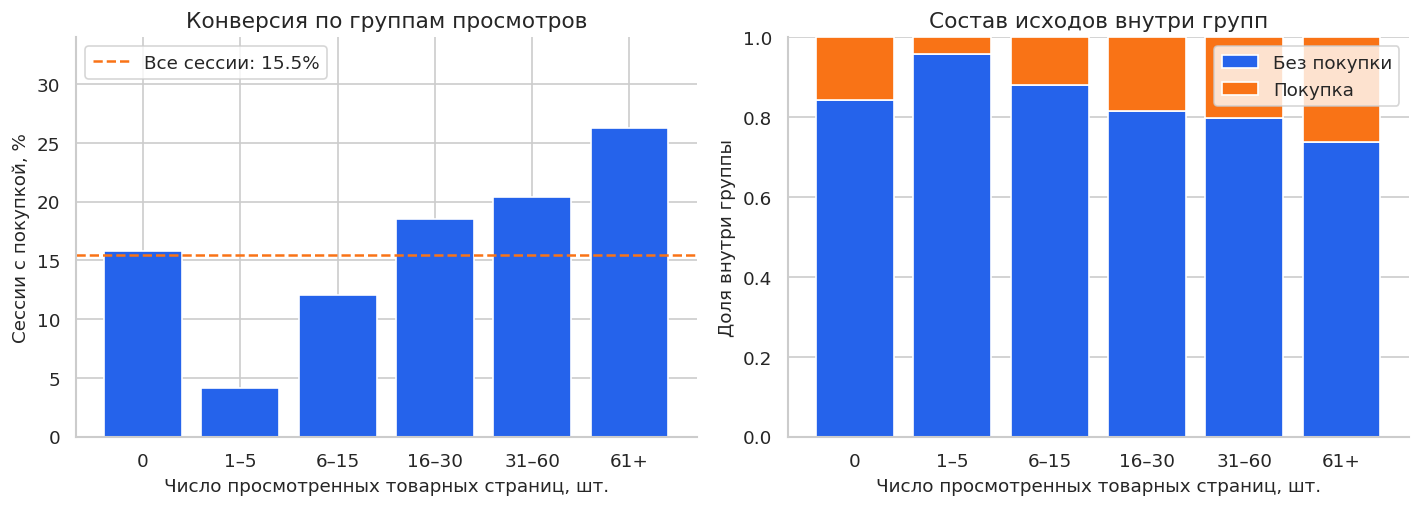

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].bar(PAGE_LABELS, conversion_by_bin.values, color=BLUE)
axes[0].axhline(100*p_hat, color=ORANGE, ls='--', label=f'Все сессии: {p_hat:.1%}')
axes[0].set(xlabel='Число просмотренных товарных страниц, шт.', ylabel='Сессии с покупкой, %',
            title='Конверсия по группам просмотров', ylim=(0, 34))
axes[0].legend(loc='upper left')
proportions = observed.div(observed.sum(axis=1), axis=0)
axes[1].bar(PAGE_LABELS, proportions[0], color=BLUE, label='Без покупки')
axes[1].bar(PAGE_LABELS, proportions[1], bottom=proportions[0], color=ORANGE, label='Покупка')
axes[1].set(xlabel='Число просмотренных товарных страниц, шт.', ylabel='Доля внутри группы',
            title='Состав исходов внутри групп', ylim=(0,1))
axes[1].legend(loc='upper right')
fig.tight_layout()
plt.show()

### 4.1. Что получилось

В группе с 1–5 просмотренными страницами покупку совершили 4,12% пользователей, в группе с 61 и более страницами 26,24%. Критерий дал $\chi^2=468{,}93$ при $p\approx4{,}05\cdot10^{-99}$. Гипотезу независимости отклоняем. При этом $V=0{,}195$: очень малое p-value не означает сильной связи.

При $X=0$ всего 38 сессий, поэтому эту группу отдельно не интерпретируем. Полученная связь не доказывает, что увеличение числа просмотров вызывает покупку. На оба показателя может влиять интерес к товарам.

<a id="sampling"></a>

## 5. Выборка и состоятельность оценок

В качестве конечной генеральной совокупности возьмём весь CSV. Его среднее $\mu_N=\frac1N\sum X_i$ и доля покупок $p_N=\frac1N\sum Y_i$ известны. Извлечём подвыборки размера $n$ двумя способами:

- с возвращением: строка может попасть в выборку несколько раз;
- без возвращения: одну строку выбираем не более одного раза.

В обоих случаях выборочное среднее несмещённо относительно $\mu_N$. Для дисперсии $\sigma_N^2=\frac1N\sum_i(x_i-\mu_N)^2$ справедливо:

$$
\operatorname{Var}(\bar X_{n,\mathrm{возврат}})=\frac{\sigma_N^2}{n},\qquad
\operatorname{Var}(\bar X_{n,\mathrm{без\ возврата}})=
\frac{\sigma_N^2}{n}\cdot\frac{N-n}{N-1}.
$$

Множитель $(N-n)/(N-1)$ учитывает отбор без возвращения. Повторим отбор по 180 раз для каждого $n$ и сравним RMSE оценок. По мере роста выборки ошибка уменьшается; при $n=N$ и отборе без возвращения она равна нулю.

Одна конкретная простая случайная выборка без возвращения:


,Статистика,Весь наблюдённый набор,"Случайная выборка, n=1000"
0,"Среднее X, страниц",31.7315,33.216
1,"Медиана X, страниц",18.0000,20.000
2,Доля покупок Y,0.1547,0.154


,n,Схема,"RMSE X, страниц","RMSE Y, доля"
0,50,С возвращением,6.0281,0.0524
1,50,Без возвращения,6.6881,0.0470
2,100,С возвращением,4.4341,0.0340
3,100,Без возвращения,4.2180,0.0348
4,300,С возвращением,2.4572,0.0211
5,300,Без возвращения,2.6234,0.0204
6,1000,С возвращением,1.2897,0.0113
7,1000,Без возвращения,1.4454,0.0117
8,3000,С возвращением,0.8356,0.0068
9,3000,Без возвращения,0.6696,0.0058


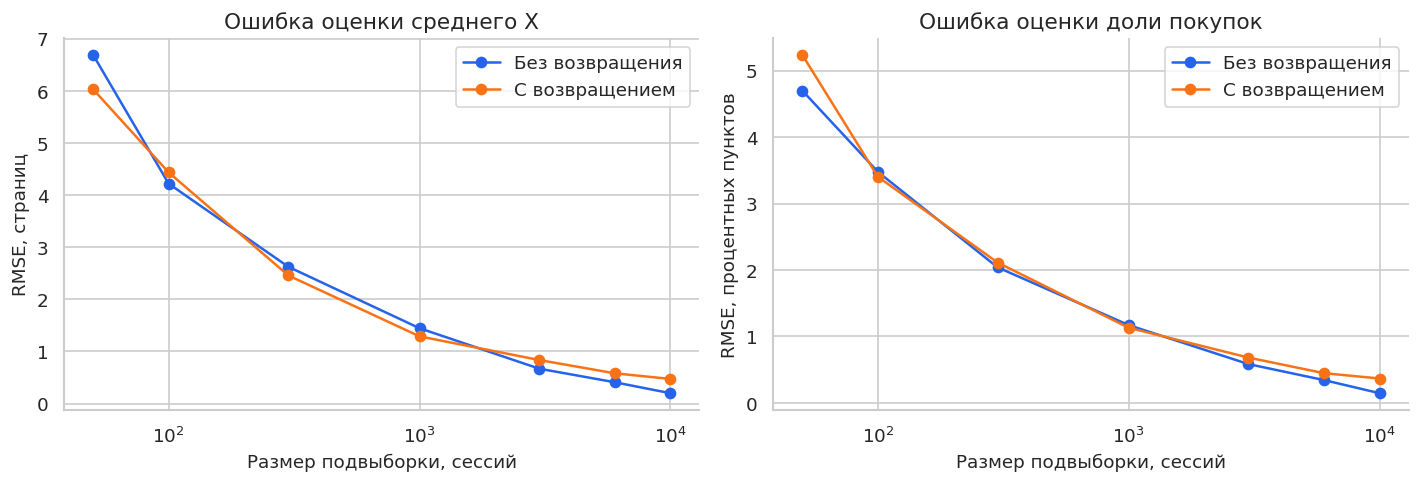

In [9]:
rng = np.random.default_rng(SEED)
one_sample_idx = rng.choice(N, size=1000, replace=False)
sample_comparison = pd.DataFrame({
    'Статистика': ['Среднее X, страниц', 'Медиана X, страниц', 'Доля покупок Y'],
    'Весь наблюдённый набор': [x.mean(), np.median(x), y.mean()],
    'Случайная выборка, n=1000': [x[one_sample_idx].mean(), np.median(x[one_sample_idx]), y[one_sample_idx].mean()]})
print('Одна конкретная простая случайная выборка без возвращения:')
display(sample_comparison.round(4))
sizes = [50, 100, 300, 1000, 3000, 6000, 10000]
repetitions = 180
records = []
for n in sizes:
    for scheme in ['С возвращением', 'Без возвращения']:
        means_x, shares_y = [], []
        for _ in range(repetitions):
            idx = rng.integers(N, size=n) if scheme == 'С возвращением' else rng.choice(N, size=n, replace=False)
            means_x.append(x[idx].mean())
            shares_y.append(y[idx].mean())
        records.append({'n':n, 'Схема':scheme, 'RMSE X, страниц':np.sqrt(np.mean((np.array(means_x)-mean_x)**2)),
                        'RMSE Y, доля':np.sqrt(np.mean((np.array(shares_y)-p_hat)**2))})
sampling_result = pd.DataFrame(records)
display(sampling_result.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for scheme, data in sampling_result.groupby('Схема'):
    axes[0].plot(data['n'], data['RMSE X, страниц'], '-o', label=scheme)
    axes[1].plot(data['n'], 100*data['RMSE Y, доля'], '-o', label=scheme)
axes[0].set(title='Ошибка оценки среднего X', xlabel='Размер подвыборки, сессий', ylabel='RMSE, страниц')
axes[1].set(title='Ошибка оценки доли покупок', xlabel='Размер подвыборки, сессий', ylabel='RMSE, процентных пунктов')
for ax in axes:
    ax.set_xscale('log'); ax.legend()
fig.tight_layout()
plt.show()

<a id="generator"></a>

## 6. Генератор случайных чисел

### 6.1. Метод обратной функции (квантильное преобразование)

Генерируем $X$, количество просмотренных товарных страниц. На гистограмме заметна правая асимметрия, поэтому нормальную модель не используем. Возьмём частоты непосредственно из данных.

Обозначим возможные значения через $x_{(1)}<\dots<x_{(m)}$, их вероятности через $p_j=n_j/N$, накопленные вероятности через $F_j=\sum_{k=1}^j p_k$. Для каждого нового значения берём $U_i\sim\mathrm{Uniform}[0,1)$:

$$X_i^*=\widehat F_N^{-1}(U_i)=\min\{x_{(j)}:\ F_j\ge U_i\}.$$

Проверим распределение полученного $X_i^*$. Событие $X_i^*\le x_{(j)}$ равносильно $U_i\le F_j$, поэтому

$$P(X_i^*\le x_{(j)})=P(U_i\le F_j)=F_j=\widehat F_N(x_{(j)}).$$

В теории вероятности совпадают с частотами CSV. При конечном числе генераций будут отклонения. В реализации `random.Random` даёт псевдослучайные числа, а двоичный поиск находит нужный квантиль.

In [10]:
model = EmpiricalGenerator.fit(x)
simulated = np.array(model.sample(10000, seed=SEED))
distance = kolmogorov_distance(model, simulated)
bound = dkw_threshold(len(simulated), alpha=.05)
comparisons = pd.DataFrame({
    'Метрика': ['Объём', 'Среднее, страниц', 'Стандартное отклонение, страниц',
                'Медиана, страниц', '90-й процентиль, страниц', 'Максимум, страниц'],
    'Реальные данные': [len(x), x.mean(), x.std(ddof=0), np.median(x), np.quantile(x,.9), x.max()],
    'Генератор': [len(simulated), simulated.mean(), simulated.std(ddof=0),
                 np.median(simulated), np.quantile(simulated,.9), simulated.max()]})
display(comparisons.round(2))
print(f'Колмогоровское расстояние D = {distance:.4f}')
print(f'DKW-граница при α=0.05, n=10000: ε = {bound:.4f}')
print(f'Эмпирическая проверка D <= ε: {distance <= bound}')

Колмогоровское расстояние D = 0.0131
DKW-граница при α=0.05, n=10000: ε = 0.0136
Эмпирическая проверка D <= ε: True


,Метрика,Реальные данные,Генератор
0,Объём,12330.00,10000.00
1,"Среднее, страниц",31.73,31.29
2,"Стандартное отклонение, страниц",44.47,45.07
3,"Медиана, страниц",18.00,17.00
4,"90-й процентиль, страниц",74.00,72.00
5,"Максимум, страниц",705.00,705.00


### 6.2. Проверка совпадения распределений

Сравним эмпирические функции распределения по максимальному расхождению $D=\sup_t|\widehat F_{\rm генератор}(t)-\widehat F_{\rm реальные}(t)|$. Обычный p-value двухвыборочного KS-теста здесь не подходит без поправок: данные дискретные, а генератор построен на исходной выборке.

Для фиксированной эмпирической модели и $n$ независимых генераций применим неравенство DKW:

$$P(D>\varepsilon)\le 2e^{-2n\varepsilon^2},\qquad
\varepsilon_{0.05}=\sqrt{\frac{\ln(2/0.05)}{2n}}.$$

При $n=10\,000$ и `seed=2026` получено $D=0{,}0131$, порог $\varepsilon_{0.05}=0{,}0136$. Расхождение укладывается в границу. Для другого `seed` результат может отличаться.

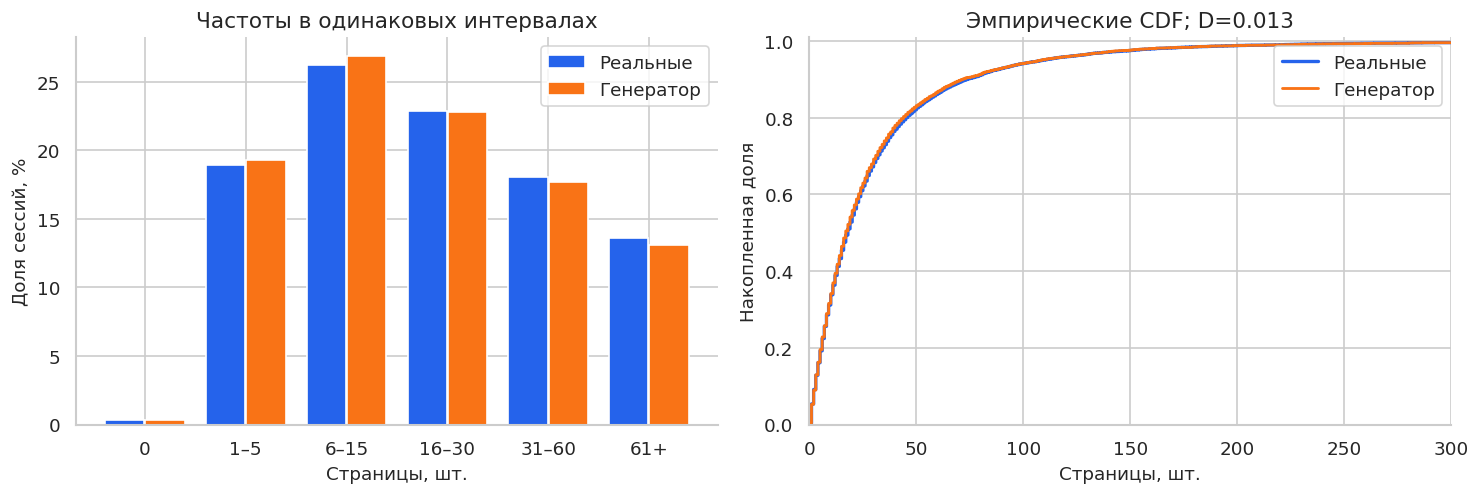

In [11]:
real_bins = pd.Series(pd.cut(x, bins=PAGE_BINS, labels=PAGE_LABELS)).value_counts(sort=False) / len(x)
generated_bins = pd.Series(pd.cut(simulated, bins=PAGE_BINS, labels=PAGE_LABELS)).value_counts(sort=False) / len(simulated)
bar_positions = np.arange(len(PAGE_LABELS))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
axes[0].bar(bar_positions-.2, real_bins*100, width=.39, label='Реальные', color=BLUE)
axes[0].bar(bar_positions+.2, generated_bins*100, width=.39, label='Генератор', color=ORANGE)
axes[0].set(xticks=bar_positions, xticklabels=PAGE_LABELS, xlabel='Страницы, шт.',
            ylabel='Доля сессий, %', title='Частоты в одинаковых интервалах')
axes[0].legend()
axes[1].step(np.sort(x), np.arange(1,N+1)/N, where='post', color=BLUE, lw=2, label='Реальные')
axes[1].step(np.sort(simulated), np.arange(1,len(simulated)+1)/len(simulated),
             where='post', color=ORANGE, lw=1.7, label='Генератор')
axes[1].set(xlabel='Страницы, шт.', ylabel='Накопленная доля', title=f'Эмпирические CDF; D={distance:.3f}',
            xlim=(0, min(300, x.max())), ylim=(0,1.01))
axes[1].legend()
fig.tight_layout()
plt.show()

### 6.3. Автотесты и marimo

Семь тестов проверяют вероятности, диапазон значений, воспроизводимость при фиксированном `seed`, обработку ошибок, совпадение частот с CSV и сходимость генератора. Запуск: `python -m unittest discover -s tests -v`.

[Открыть интерактивный генератор](index.html). В marimo можно менять количество сессий, `seed` и тип графика. Частоты из CSV встроены в приложение.

<a id="resume"></a>

## 7. Lab resume. Выводы

1. При равновероятном выборе сессии $X$ и $Y$ измеримы и имеют положительную дисперсию. Поэтому обе величины случайные в этом эксперименте.
2. Половина пользователей просмотрела не более 18 товарных страниц. Среднее выше, 31,73 страницы, из-за длинного правого хвоста.
3. Покупку совершили 1 908 пользователей из 12 330, или 15,47%.
4. Доли покупок по группам просмотров различаются ($\chi^2=468{,}93$, $p\approx4{,}05\cdot10^{-99}$). Это зависимость в данных, а не доказательство влияния просмотров на решение купить.
5. В генерации 10 000 значений расстояние между CDF составило $D=0{,}0131$ и оказалось ниже границы DKW ($0{,}0136$).

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|:--|:--|:--|:--|
| K-01 | [Случайные величины](#rv1-description) | выполнено | Пространство исходов, измеримость, дисперсии |
| K-02 | [Зависимость](#independence) | выполнено | Таблица сопряжённости, $\chi^2$, p-value, V Крамера |
| K-03 | [EDA](#rv1-eda) | выполнено | Графики, квантили, нормализация |
| K-04 | [Генератор](#generator) | выполнено | Обратная CDF, вывод, сравнение метрик |
| K-05 | [marimo](#generator) | выполнено | Ползунки и два вида графика |
| K-06 | [Оформление](#top) | выполнено | Оглавление, LaTeX, единицы измерения |
| K-07 | [Оценки](#sampling) | дополнительно | Отбор с возвращением и без, RMSE |
| K-08 | [Тесты](#generator) | дополнительно | 7 автотестов |

**Ограничение:** данные собраны в одном магазине. По ним нельзя утверждать, что такое же поведение будет у пользователей других сайтов.

<a id="sources"></a>

## 8. Литература

1. Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [DOI: 10.24432/C5F88Q](https://doi.org/10.24432/C5F88Q). Лицензия исходных данных: CC BY 4.0.
2. Devroye, L. (1986). *Non-Uniform Random Variate Generation*. Springer. Глава II, раздел об inversion method. [Полный текст, страница автора](https://luc.devroye.org/rnbookindex.html).
3. Dvoretzky, A., Kiefer, J., Wolfowitz, J. (1956). *Asymptotic minimax character of the sample distribution function and of the classical multinomial estimator*. Annals of Mathematical Statistics, 27(3), 642–669. Константа $2$ в границе соответствует уточнению Массара (1990).
4. Wilson, E. B. (1927). *Probable inference, the law of succession, and statistical inference*. Journal of the American Statistical Association, 22(158), 209–212.
5. [Python `random`: Mersenne Twister](https://docs.python.org/3/library/random.html).
6. [marimo: интерактивные элементы](https://docs.marimo.io/guides/interactivity/) и [экспорт интерактивного HTML](https://docs.marimo.io/guides/exporting/webassembly_html/).

[↑ Вернуться к содержанию](#top)